# Preparação do Ambiente

In [1]:
import pandas as pd

In [2]:
url = 'https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv'

# Entrada

In [3]:
df = pd.read_csv(url)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

# Análise dos dados

Detalhes dos dados

- Amount: Valor da transação

- Class 0: transação não fraudulenta
- Class 1: transação possívelmente fraudulenta

In [5]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [6]:
df[['Class']].value_counts()

,count
Class,
0,284315
1,492


In [7]:
df[['Class']].value_counts(
    normalize=True
)

,proportion
Class,
0,0.998273
1,0.001727


Notamos que há um grande desbalanceamento.

# Transformação

In [9]:
import numpy as np

In [11]:
df['Amount_Log'] = np.log1p(df['Amount'])

In [13]:
df[['Amount_Log']].head()

,Amount_Log
0,5.014760
1,1.305626
2,5.939276
3,4.824306
4,4.262539


In [14]:
from sklearn.preprocessing import StandardScaler

In [15]:
scaler = StandardScaler()

In [16]:
df['Amount_Scaled'] = scaler.fit_transform(df[['Amount']])

In [17]:
df[['Amount_Scaled']].head()

,Amount_Scaled
0,0.244964
1,-0.342475
2,1.160686
3,0.140534
4,-0.073403


# Divisão do conjunto de dados (treinamento e teste)

In [18]:
from sklearn.model_selection import train_test_split

In [92]:
X = df.drop('Class', axis=1)

In [93]:
y = df['Class']

In [94]:
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.3, random_state=42)

# Avaliação do Modelo de Regressão Logística

In [22]:
from sklearn.linear_model import LogisticRegression

In [23]:
model = LogisticRegression(
    max_iter=1_000
)

In [24]:
model.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=1000)

In [25]:
y_pred = model.predict(X_test)

In [28]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.84      0.66      0.73       148

    accuracy                           1.00     85443
   macro avg       0.92      0.83      0.87     85443
weighted avg       1.00      1.00      1.00     85443



Como o modelo está desbalanceado, precisamos analisar precision e recall.

In [29]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

In [30]:
y_probs = model.predict_proba(X_test)[:,1]

In [31]:
fpr, tpr, _ = roc_curve(y_test, y_probs)

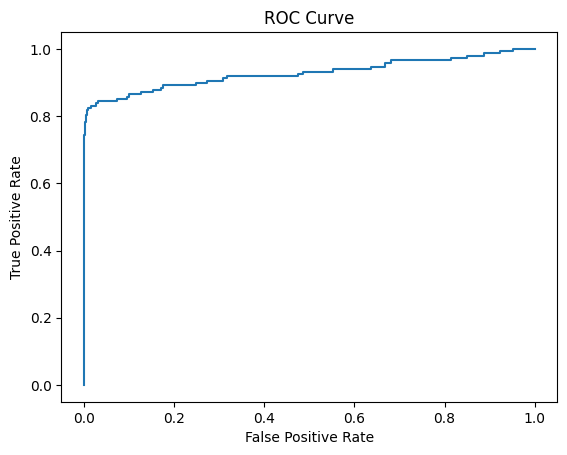

In [34]:
plt.plot(fpr, tpr)
plt.title('ROC Curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.show()

In [35]:
print('AUC: ', roc_auc_score(y_test, y_probs))

AUC:  0.9272042339543365


In [36]:
from sklearn.metrics import precision_recall_curve

In [37]:
precision, recall, _ = precision_recall_curve(y_test, y_probs)

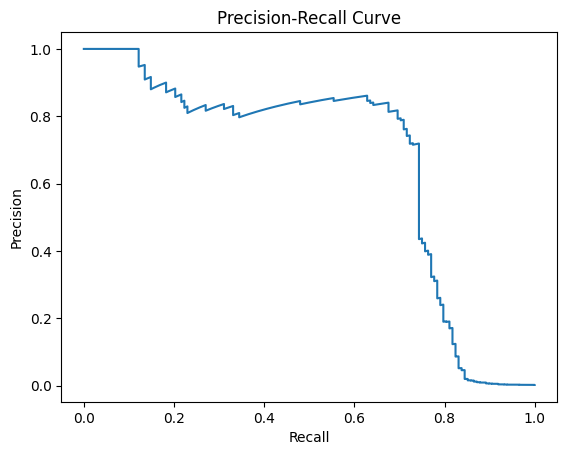

In [39]:
plt.plot(recall, precision)
plt.title('Precision-Recall Curve')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.show()

# Estratégias de Balanceamento

## Undersampling

In [40]:
fraudes = df[df['Class'] == 1]
nao_fraudes = df[df['Class'] == 0].sample(len(fraudes), random_state=42)

df_undersampling = pd.concat([fraudes, nao_fraudes])

In [42]:
df_undersampling[['Class']].value_counts()

,count
Class,
0,492
1,492


## Oversampling

In [43]:
from imblearn.over_sampling import SMOTE

In [44]:
smote = SMOTE()

X_smote, y_smote = smote.fit_resample(X, y)

In [45]:
y_smote.value_counts()

,count
Class,
0,284315
1,284315


# Novo teste de regressão logística com Undersampling



In [52]:
X_undersampling = df_undersampling.drop('Class', axis=1)

In [53]:
y_undersampling = df_undersampling['Class']

In [65]:
X_train_under, X_test_under, y_train_under, y_test_under = train_test_split(X_undersampling, y_undersampling, stratify=y_undersampling, test_size=0.3, random_state=42)

In [66]:
model_under = LogisticRegression(
    max_iter=1_000
)

In [67]:
model_under.fit(X_train_under, y_train_under)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=1000)

In [68]:
y_pred_under = model_under.predict(X_test_under)

In [69]:
print(classification_report(y_test_under, y_pred_under))

              precision    recall  f1-score   support

           0       0.93      0.95      0.94       148
           1       0.95      0.93      0.94       148

    accuracy                           0.94       296
   macro avg       0.94      0.94      0.94       296
weighted avg       0.94      0.94      0.94       296



In [71]:
y_probs_under = model_under.predict_proba(X_test_under)[:,1]

In [72]:
fpr_under, tpr_under, _ = roc_curve(y_test_under, y_probs_under)

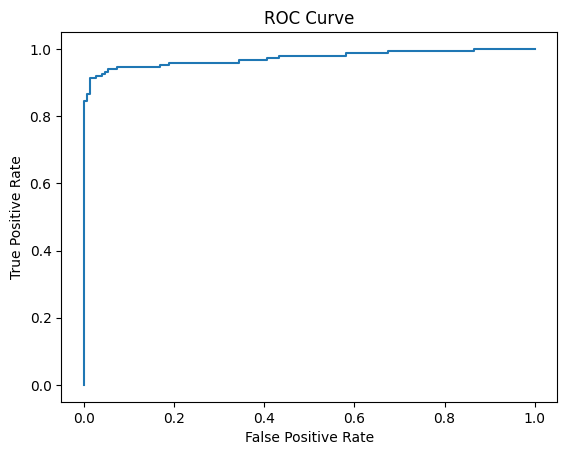

In [73]:
plt.plot(fpr_under, tpr_under)
plt.title('ROC Curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.show()

In [74]:
print('AUC: ', roc_auc_score(y_test_under, y_probs_under))

AUC:  0.972836011687363


In [75]:
precision_under, recall_under, _ = precision_recall_curve(y_test_under, y_probs_under)

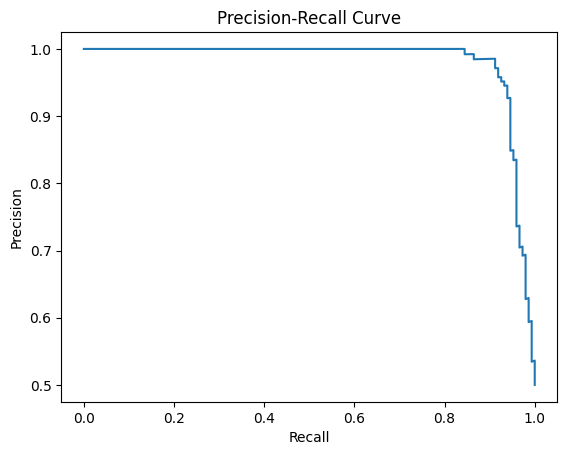

In [76]:
plt.plot(recall_under, precision_under)
plt.title('Precision-Recall Curve')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.show()

# Novo teste de regressão logística com Oversampling

In [77]:
X_train_over, X_test_over, y_train_over, y_test_over = train_test_split(X_smote, y_smote, stratify=y_smote, test_size=0.3, random_state=42)

In [78]:
model_over = LogisticRegression(
    max_iter=1_000
)

In [79]:
model_over.fit(X_train_over, y_train_over)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=1000)

In [80]:
y_pred_over = model_over.predict(X_test_over)

In [81]:
print(classification_report(y_test_over, y_pred_over))

              precision    recall  f1-score   support

           0       0.97      0.99      0.98     85295
           1       0.99      0.97      0.98     85294

    accuracy                           0.98    170589
   macro avg       0.98      0.98      0.98    170589
weighted avg       0.98      0.98      0.98    170589



In [82]:
y_probs_over = model_over.predict_proba(X_test_over)[:,1]

In [83]:
fpr_over, tpr_over, _ = roc_curve(y_test_over, y_probs_over)

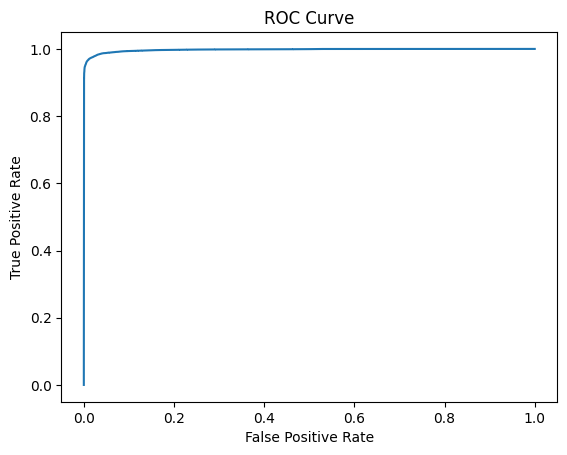

In [84]:
plt.plot(fpr_over, tpr_over)
plt.title('ROC Curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.show()

In [85]:
print('AUC: ', roc_auc_score(y_test_over, y_probs_over))

AUC:  0.9973316454116071


In [86]:
precision_over, recall_over, _ = precision_recall_curve(y_test_over, y_probs_over)

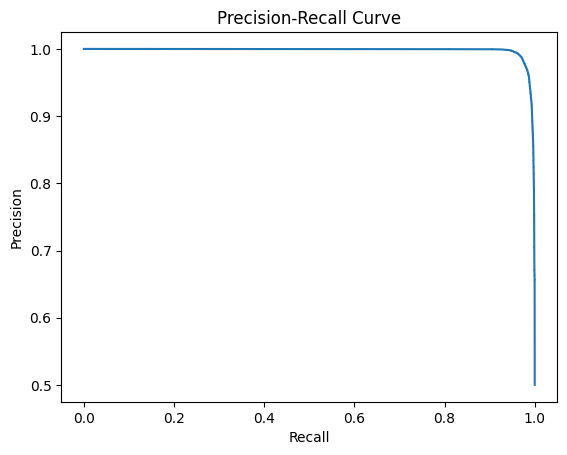

In [87]:
plt.plot(recall_over, precision_over)
plt.title('Precision-Recall Curve')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.show()

# Teste de Random Forest com os dados iniciais



In [90]:
from sklearn.ensemble import RandomForestClassifier

In [95]:
modelo_random_forest = RandomForestClassifier(
    n_estimators=50,
    max_depth=10,
    class_weight='balanced',
    n_jobs=1,
    random_state=42,
)

In [96]:
modelo_random_forest.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', max_depth=10, n_estimators=50,
                       n_jobs=1, random_state=42)

In [97]:
y_pred_random_forest = modelo_random_forest.predict(X_test)

In [98]:
print(classification_report(y_test, y_pred_random_forest))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.84      0.76      0.79       148

    accuracy                           1.00     85443
   macro avg       0.92      0.88      0.90     85443
weighted avg       1.00      1.00      1.00     85443



In [107]:
y_probs_random_forest = modelo_random_forest.predict_proba(X_test)[:,1]

In [108]:
fpr_random_forest, tpr_random_forest, _ = roc_curve(y_test, y_probs_random_forest)

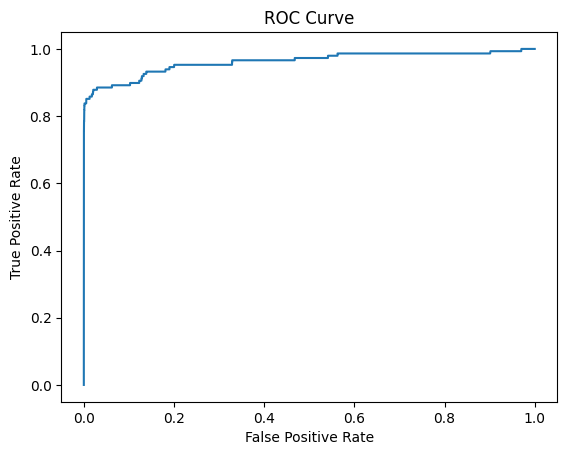

In [109]:
plt.plot(fpr_random_forest, tpr_random_forest)
plt.title('ROC Curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.show()

In [111]:
print('AUC: ', roc_auc_score(y_test, y_probs_random_forest))

AUC:  0.9620539922653177


In [113]:
precision_random_forest, recall_random_forest, _ = precision_recall_curve(y_test, y_probs_random_forest)

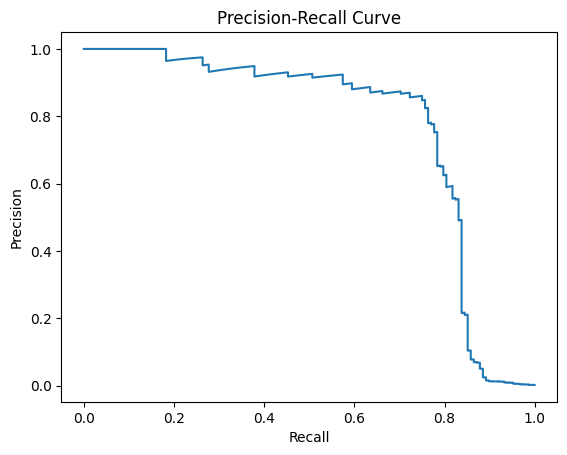

In [114]:
plt.plot(recall_random_forest, precision_random_forest)
plt.title('Precision-Recall Curve')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.show()

# Teste de Random Forest com Undersampling

In [99]:
modelo_random_forest_under = RandomForestClassifier(
    n_estimators=50,
    max_depth=10,
    class_weight='balanced',
    n_jobs=1,
    random_state=42,
)

In [100]:
modelo_random_forest_under.fit(X_train_under, y_train_under)

RandomForestClassifier(class_weight='balanced', max_depth=10, n_estimators=50,
                       n_jobs=1, random_state=42)

In [101]:
y_pred_random_forest_under = modelo_random_forest_under.predict(X_test_under)

In [102]:
print(classification_report(y_test_under, y_pred_random_forest_under))

              precision    recall  f1-score   support

           0       0.91      0.97      0.94       148
           1       0.96      0.91      0.93       148

    accuracy                           0.94       296
   macro avg       0.94      0.94      0.94       296
weighted avg       0.94      0.94      0.94       296



In [115]:
y_probs_random_forest_under = modelo_random_forest_under.predict_proba(X_test_under)[:,1]

In [116]:
fpr_random_forest_under, tpr_random_forest_under, _ = roc_curve(y_test_under, y_probs_random_forest_under)

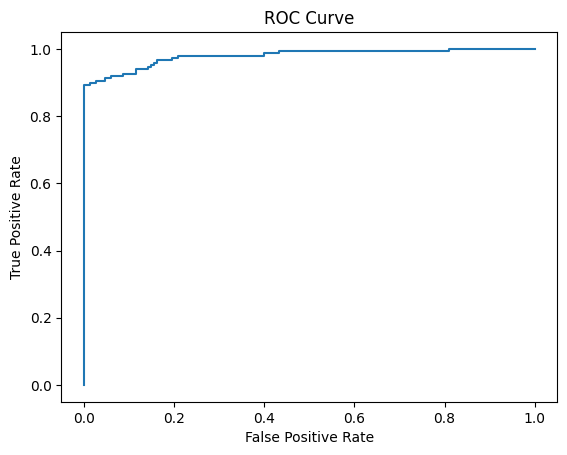

In [117]:
plt.plot(fpr_random_forest_under, tpr_random_forest_under)
plt.title('ROC Curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.show()

In [118]:
print('AUC: ', roc_auc_score(y_test_under, y_probs_random_forest_under))

AUC:  0.9789079620160701


In [119]:
precision_random_forest_under, recall_random_forest_under, _ = precision_recall_curve(y_test_under, y_probs_random_forest_under)

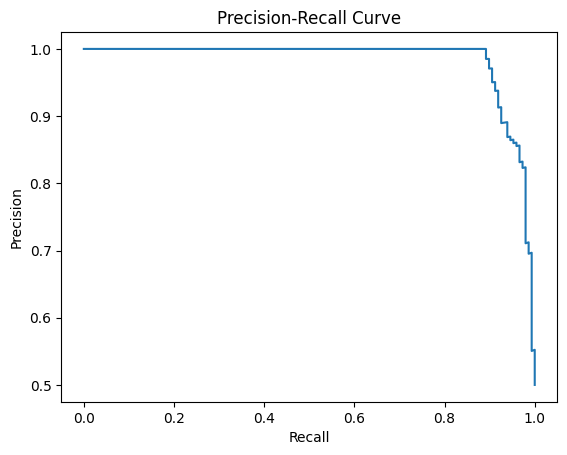

In [120]:
plt.plot(recall_random_forest_under, precision_random_forest_under)
plt.title('Precision-Recall Curve')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.show()

# Teste de Random Forest com Oversampling

In [103]:
modelo_random_forest_over = RandomForestClassifier(
    n_estimators=50,
    max_depth=10,
    class_weight='balanced',
    n_jobs=1,
    random_state=42,
)

In [104]:
modelo_random_forest_over.fit(X_train_over, y_train_over)

RandomForestClassifier(class_weight='balanced', max_depth=10, n_estimators=50,
                       n_jobs=1, random_state=42)

In [105]:
y_pred_random_forest_over = modelo_random_forest_over.predict(X_test_over)

In [106]:
print(classification_report(y_test_over, y_pred_random_forest_over))

              precision    recall  f1-score   support

           0       0.98      1.00      0.99     85295
           1       1.00      0.98      0.99     85294

    accuracy                           0.99    170589
   macro avg       0.99      0.99      0.99    170589
weighted avg       0.99      0.99      0.99    170589



In [121]:
y_probs_random_forest_over = modelo_random_forest_over.predict_proba(X_test_over)[:,1]

In [122]:
fpr_random_forest_over, tpr_random_forest_over, _ = roc_curve(y_test_over, y_probs_random_forest_over)

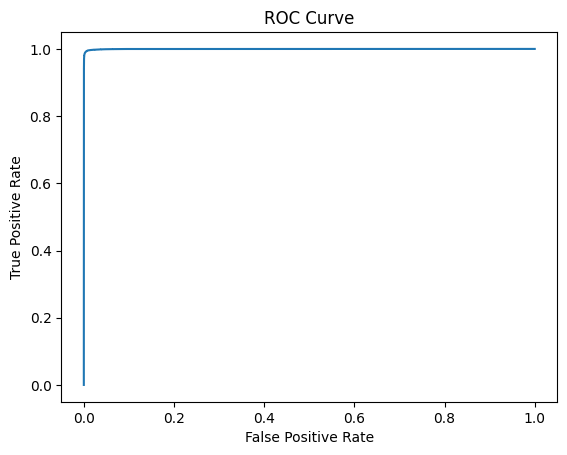

In [123]:
plt.plot(fpr_random_forest_over, tpr_random_forest_over)
plt.title('ROC Curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.show()

In [124]:
print('AUC: ', roc_auc_score(y_test_over, y_probs_random_forest_over))

AUC:  0.9997221548670023


In [125]:
precision_random_forest_over, recall_random_forest_over, _ = precision_recall_curve(y_test_over, y_probs_random_forest_over)

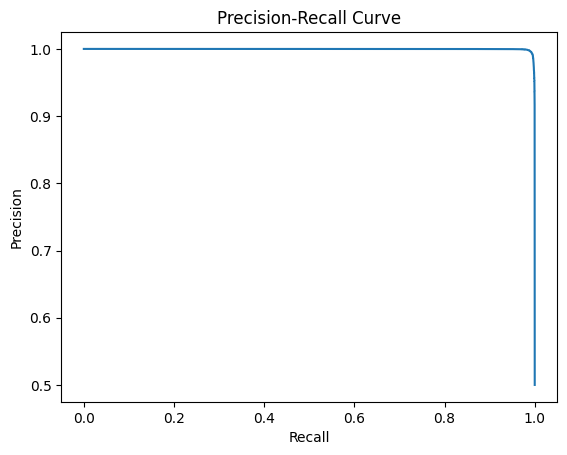

In [126]:
plt.plot(recall_random_forest_over, precision_random_forest_over)
plt.title('Precision-Recall Curve')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.show()

# Teste de XGBoost

In [127]:
from xgboost import XGBClassifier

In [128]:
modelo_xgboost = XGBClassifier(
    scale_pos_weight=10,
    use_label_encoder=False,
    eval_metric='logloss'
)

In [129]:
modelo_xgboost.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [17:20:25] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, ...)

In [130]:
y_pred_xgboost = modelo_xgboost.predict(X_test)

In [131]:
print(classification_report(y_test, y_pred_xgboost))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.94      0.78      0.85       148

    accuracy                           1.00     85443
   macro avg       0.97      0.89      0.93     85443
weighted avg       1.00      1.00      1.00     85443



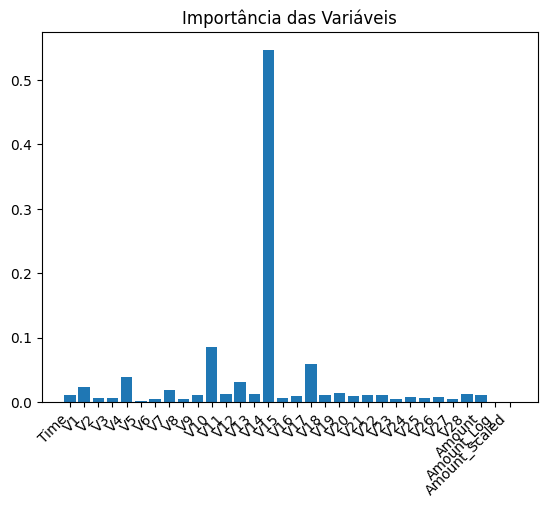

In [138]:
plt.bar(df.drop('Class', axis=1).columns, modelo_xgboost.feature_importances_)
plt.title('Importância das Variáveis')
plt.xticks(rotation=45, ha='right')
plt.show()

In [139]:
from sklearn.model_selection import GridSearchCV

In [140]:
param_grid = {
    'max_depth': [3, 5],
    'n_estimators': [50, 100],
}

In [141]:
grid = GridSearchCV(
    XGBClassifier(eval_metric='logloss'),
    param_grid,
    scoring='recall',
    cv=3,
)

In [142]:
grid.fit(X_train, y_train)

GridSearchCV(cv=3,
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=None, device=None,
                                     early_stopping_rounds=None,
                                     enable_categorical=True,
                                     eval_metric='logloss', feature_types=None,
                                     feature_weights=None, gamma=None,
                                     grow_policy=None, importance_type=None,
                                     interaction_constraints=None,
                                     learning_rate=None, max_bin=None,
                                     max_cat_threshold=None,
                                     max_cat_to_onehot=None,
                                     max_delta_step=None, max_depth=None,
                                     max_leaves=None, min_child_weight=None,
                                     missing=nan, monotone_constraints=None,
                                     multi_strategy=None, n_estimators=None,
                                     n_jobs=None, num_parallel_tree=None, ...),
             param_grid={'max_depth': [3, 5], 'n_estimators': [50, 100]},
             scoring='recall')

In [143]:
print('Melhor modelo: ', grid.best_params_)

Melhor modelo:  {'max_depth': 5, 'n_estimators': 100}


In [145]:
import shap

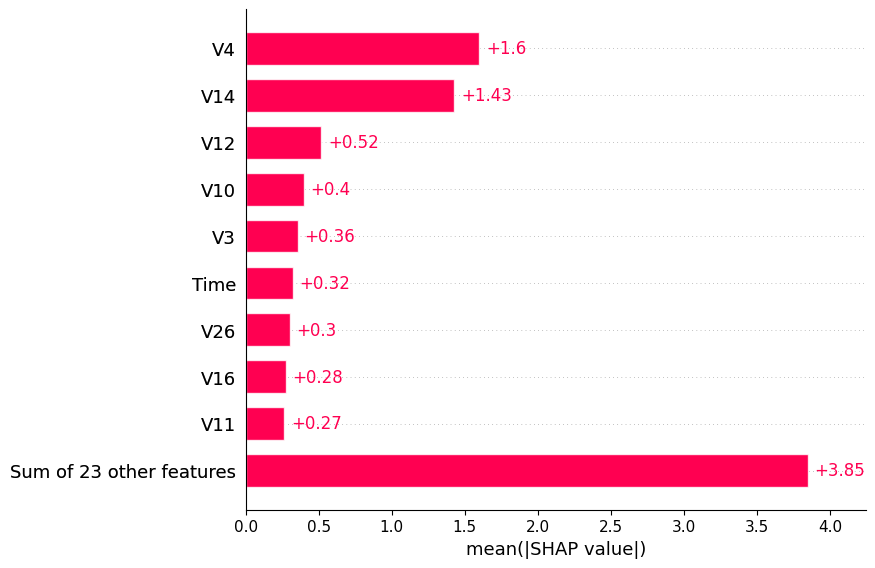

In [146]:
explainer = shap.Explainer(modelo_xgboost)
shap_values = explainer(X_test[:100])
shap.plots.bar(shap_values)